# 03 — Analyse exploratoire des variations saisonnières

## Objectifs

Cette troisième analyse exploratoire prolonge les études journalière et hebdomadaire réalisées dans les notebooks précédents.

Les premières analyses ont montré que la consommation énergétique dépend fortement des cycles horaires, du jour de la semaine et du type de bâtiment. En revanche, l'étude sur 24 heures n'a pas permis de mettre en évidence une influence indépendante de la température sur la consommation.

Un premier test historique sur plusieurs mois a néanmoins révélé des variations importantes de température et d'humidité, suggérant l'existence de phénomènes saisonniers dans les données synthétiques EnerVision.

Cette étude vise donc à :

- Examiner l'évolution des conditions environnementales sur plusieurs mois.
- Étudier les variations de consommation selon les périodes de l'année.
- Comparer les comportements saisonniers des différentes catégories de bâtiments.
- Rechercher d'éventuelles relations non linéaires entre température et consommation.
- Identifier les variables pertinentes pour notre futur modèle de prévision à 24 heures.

## Périmètre initial

- Source : API EnerVision (`/api/v1/readings`)
- Sites : SITE001 à SITE007
- Période : janvier à octobre 2026
- Échantillonnage : une journée par mois, choisie selon le même jour de semaine
- Volume théorique : 70 000 observations
- Stockage : `data/raw/yearly/`

Les données sont synthétiques et peuvent être régénérées par l'API. L'étude vise donc principalement à caractériser le comportement du simulateur et à identifier des hypothèses de modélisation, sans prétendre démontrer des relations causales applicables à des bâtiments réels.

Les journées échantillonnées ne permettent pas, à elles seules, d'estimer une véritable moyenne mensuelle.

In [46]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path("../data/raw/yearly")

files = sorted(DATA_DIR.glob("SITE*.json"))

if not files:
    raise FileNotFoundError(
        f"Aucune donnée saisonnière trouvée dans {DATA_DIR.resolve()}. "
        "Exécuter scripts/collect_seasonal_readings.py au préalable."
    )

records = []

for path in files:
    with path.open(encoding="utf-8") as file:
        payload = json.load(file)

    records.extend(payload["readings"])

df = pd.DataFrame(records)

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    utc=True,
    format="ISO8601",
)

df["month"] = df["timestamp"].dt.month
df["hour"] = df["timestamp"].dt.hour

print(f"Fichiers chargés : {len(files)}")
print(f"Observations : {len(df)}")
print(f"Sites : {df['site_id'].nunique()}")

display(df.head())

Fichiers chargés : 70
Observations : 70000
Sites : 7


,timestamp,site_id,site_type,consumption_kw,consumption_kwh,voltage_v,current_a,power_factor,temperature_celsius,humidity_percent,null_reasons,data_quality,month,hour
0,2026-01-07 00:00:00+00:00,SITE001,office,121.55,121.55,406.9,181.56,0.887,10.8,74.1,[],good,1,0
1,2026-01-07 00:01:26.400000+00:00,SITE001,office,138.93,138.93,393.4,214.61,0.951,9.6,66.4,[],good,1,0
2,2026-01-07 00:02:52.800000+00:00,SITE001,office,134.67,134.67,392.8,208.35,0.948,8.2,62.1,[],good,1,0
3,2026-01-07 00:04:19.200000+00:00,SITE001,office,145.06,145.06,397.1,222.04,0.885,8.6,80.7,[],good,1,0
4,2026-01-07 00:05:45.600000+00:00,SITE001,office,149.58,149.58,394.4,230.51,0.930,10.2,70.8,[],good,1,0


A - Collecte des données

In [47]:
import json
from datetime import UTC, datetime, timedelta
from pathlib import Path

from smart_energy_ml.ingestion.enervision_client import EnerVisionClient

OUTPUT_DIR = Path("../data/raw/yearly")


def first_wednesday(year: int, month: int) -> datetime:
    date = datetime(year, month, 1, tzinfo=UTC)

    while date.weekday() != 2:
        date += timedelta(days=1)

    return date


def main():
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    with EnerVisionClient() as client:
        for month in range(1, 11):
            start = first_wednesday(2026, month)
            end = start + timedelta(days=1)

            for site_number in range(1, 8):
                site_id = f"SITE{site_number:03d}"

                path = OUTPUT_DIR / (f"{site_id}_{start.strftime('%Y%m%d')}.json")

                # Évite de régénérer les données déjà collectées.
                if path.exists():
                    print(f"Déjà présent : {path.name}")
                    continue

                readings = client.get_readings(
                    site_id=site_id,
                    start=start,
                    end=end,
                    limit=1000,
                )

                output = {
                    "site_id": site_id,
                    "collected_at": datetime.now(UTC).isoformat(),
                    "period_start": start.isoformat(),
                    "period_end": end.isoformat(),
                    "readings": readings,
                }

                path.write_text(
                    json.dumps(output, indent=2, ensure_ascii=False),
                    encoding="utf-8",
                )

                print(f"{site_id} — {start.date()} : {len(readings)} mesures")


if __name__ == "__main__":
    main()

Déjà présent : SITE001_20260107.json
Déjà présent : SITE002_20260107.json
Déjà présent : SITE003_20260107.json
Déjà présent : SITE004_20260107.json
Déjà présent : SITE005_20260107.json
Déjà présent : SITE006_20260107.json
Déjà présent : SITE007_20260107.json
Déjà présent : SITE001_20260204.json
Déjà présent : SITE002_20260204.json
Déjà présent : SITE003_20260204.json
Déjà présent : SITE004_20260204.json
Déjà présent : SITE005_20260204.json
Déjà présent : SITE006_20260204.json
Déjà présent : SITE007_20260204.json
Déjà présent : SITE001_20260304.json
Déjà présent : SITE002_20260304.json
Déjà présent : SITE003_20260304.json
Déjà présent : SITE004_20260304.json
Déjà présent : SITE005_20260304.json
Déjà présent : SITE006_20260304.json
Déjà présent : SITE007_20260304.json
Déjà présent : SITE001_20260401.json
Déjà présent : SITE002_20260401.json
Déjà présent : SITE003_20260401.json
Déjà présent : SITE004_20260401.json
Déjà présent : SITE005_20260401.json
Déjà présent : SITE006_20260401.json
D

## 1 — Chargement et validation des données

Cette première étape consiste à charger les mesures énergétiques collectées pour les sept sites EnerVision sur dix mois, de janvier à octobre 2026.

L'échantillon comprend une journée par mois, correspondant au premier mercredi, afin de limiter les variations liées au jour de la semaine.

L'objectif est de vérifier la complétude du jeu de données, sa répartition entre les sites et les mois, ainsi que la cohérence des périodes collectées.

Les données sont chargées depuis les fichiers JSON enregistrés dans `data/raw/yearly/`. Aucun appel à l'API n'est effectué dans ce notebook.

Cette collecte constitue un **échantillonnage saisonnier**, et non un historique annuel continu. Les résultats devront être interprétés en conséquence.

## A — Collecte des données saisonnières

### Préparation du jeu de données

Cette étude repose sur des mesures énergétiques issues de l'API EnerVision, collectées pour les sept sites sur une période allant de janvier à octobre 2026.

Afin d'étudier les variations saisonnières tout en limitant les différences liées au jour de la semaine, nous avons retenu **le premier mercredi de chaque mois**, avec 1 000 observations par site et par journée.

Le jeu de données attendu comprend donc 70 fichiers JSON, représentant environ 70 000 observations.

### Exécution préalable

La collecte est réalisée indépendamment du notebook, à l'aide du script `scripts/collect_seasonal_readings.py`.

Depuis le répertoire `ml/`, exécuter :

```powershell
python scripts/collect_seasonal_readings.py
```

Les données sont enregistrées dans :

```text
ml/data/raw/yearly/
```

Le script vérifie l'existence des fichiers avant chaque collecte afin d'éviter de régénérer les données déjà récupérées.

### Séparation des responsabilités

Ce notebook n'effectue aucun appel à l'API EnerVision. Il exploite uniquement les fichiers JSON précédemment collectés.

Cette organisation permet de garantir la reproductibilité des analyses, de préserver les données brutes et de dissocier les opérations d'ingestion des traitements exploratoires.

**Prérequis :** les fichiers de collecte saisonnière doivent être présents dans `data/raw/yearly/` avant l'exécution des cellules suivantes.

2 — Analyse des variations saisonnières
L'objectif de cette étape est d'identifier les variations de température et d'humidité au cours des dix mois étudiés.

Nous chercherons notamment à déterminer si ces variables présentent une évolution saisonnière et si cette évolution est similaire entre les différents sites.

Les moyennes calculées représentent uniquement les journées échantillonnées et ne doivent pas être interprétées comme des moyennes mensuelles complètes.

A - Moyenne par mois 

In [48]:
monthly_weather = (
    df.groupby(["month", "site_id"])[["temperature_celsius", "humidity_percent"]]
    .mean()
    .reset_index()
)

display(monthly_weather.head(14))

,month,site_id,temperature_celsius,humidity_percent
0,1,SITE001,15.077704,70.222629
1,1,SITE002,14.894137,70.169122
2,1,SITE003,14.977640,69.925950
3,1,SITE004,14.869451,69.944854
4,1,SITE005,14.976123,70.022451
5,1,SITE006,14.934763,69.722125
6,1,SITE007,15.036685,69.964912
7,2,SITE001,20.075221,77.298370
8,2,SITE002,19.990011,77.163290
9,2,SITE003,19.991068,77.372216


B - Evolution de la température

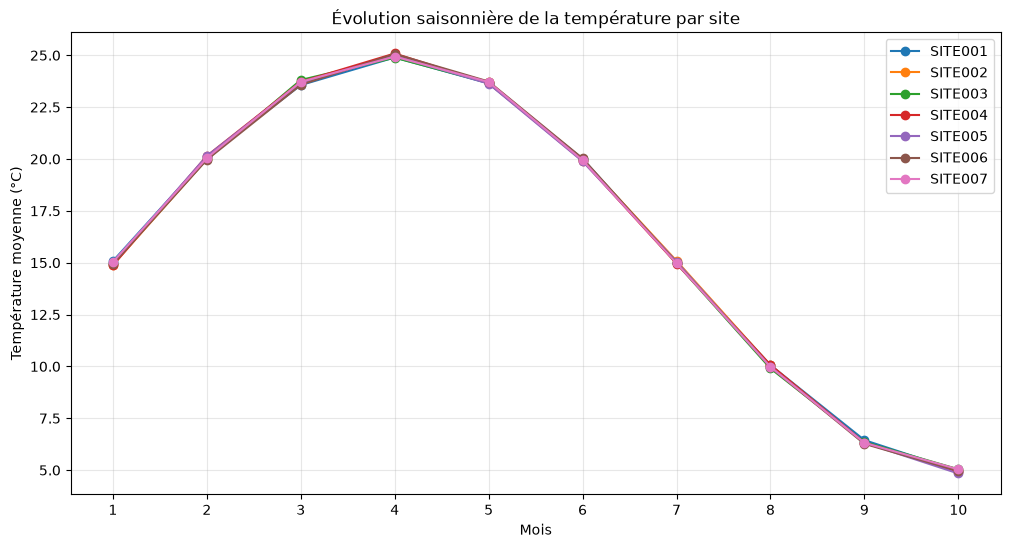

In [49]:
plt.figure(figsize=(12, 6))

for site_id, group in monthly_weather.groupby("site_id"):
    plt.plot(
        group["month"],
        group["temperature_celsius"],
        marker="o",
        label=site_id,
    )

plt.title("Évolution saisonnière de la température par site")
plt.xlabel("Mois")
plt.ylabel("Température moyenne (°C)")
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

C - Evolution de l'humidité

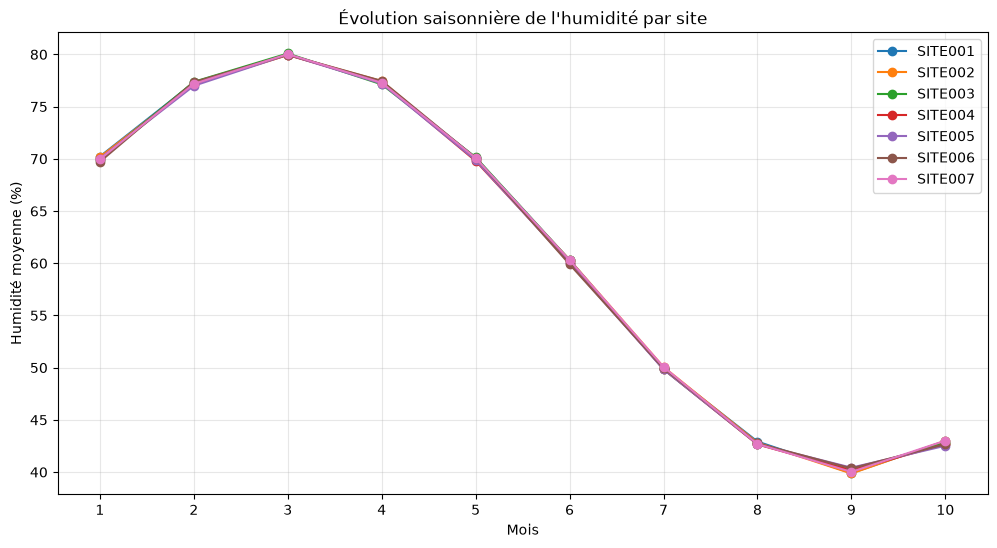

In [50]:
plt.figure(figsize=(12, 6))

for site_id, group in monthly_weather.groupby("site_id"):
    plt.plot(
        group["month"],
        group["humidity_percent"],
        marker="o",
        label=site_id,
    )

plt.title("Évolution saisonnière de l'humidité par site")
plt.xlabel("Mois")
plt.ylabel("Humidité moyenne (%)")
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Observations

L'analyse des données météorologiques met en évidence une évolution saisonnière marquée de la température et de l'humidité entre janvier et octobre 2026.

Les sept sites présentent des profils quasiment identiques, ce qui suggère l'utilisation d'un modèle météorologique commun dans le générateur de données synthétiques EnerVision.

La température moyenne varie approximativement entre 5 °C et 25 °C, tandis que l'humidité évolue entre 40 % et 80 %.

Ces variations justifient d'étudier l'influence potentielle des conditions environnementales sur la consommation électrique. Leur pouvoir prédictif reste toutefois à démontrer.

Les résultats doivent être interprétés avec prudence : les données sont synthétiques et chaque mois n'est représenté que par une seule journée d'observation.

## 3 — Analyse saisonnière de la consommation énergétique

Après avoir identifié les variations saisonnières de la température et de l'humidité, nous allons étudier l'évolution de la consommation électrique des sept sites EnerVision sur la même période.

### Objectifs

Cette analyse vise à :

- Identifier les éventuelles variations saisonnières de la consommation électrique.
- Comparer les comportements des différents sites en fonction de leur activité (bureaux, usines, datacenter, commerce et hôpital).
- Rechercher de premières correspondances entre les évolutions météorologiques et les besoins énergétiques.
- Évaluer l'intérêt d'intégrer des variables saisonnières et environnementales dans notre futur modèle prédictif.

### Méthodologie

Pour chaque site, nous calculons la puissance moyenne consommée (`consumption_kw`) sur la journée échantillonnée de chaque mois, de janvier à octobre 2026.

Les résultats seront représentés graphiquement afin de comparer les évolutions temporelles entre les sites.

Dans un second temps, nous pourrons normaliser les consommations pour comparer leurs variations relatives, indépendamment des différences de puissance entre les installations.

### Hypothèses à vérifier

Nous chercherons notamment à déterminer si les sites dont l'activité dépend des horaires de travail présentent une évolution différente de celle des infrastructures fonctionnant en continu.

Nous examinerons également l'hypothèse d'une relation non linéaire entre température et consommation, notamment une éventuelle augmentation des besoins énergétiques aux températures les plus basses ou les plus élevées.

**Limites de l'analyse :** les données utilisées sont synthétiques et ne représentent qu'une journée par mois. Les moyennes obtenues ne constituent donc pas des moyennes mensuelles et les relations observées ne pourront pas, à elles seules, établir un lien de causalité entre météo et consommation.

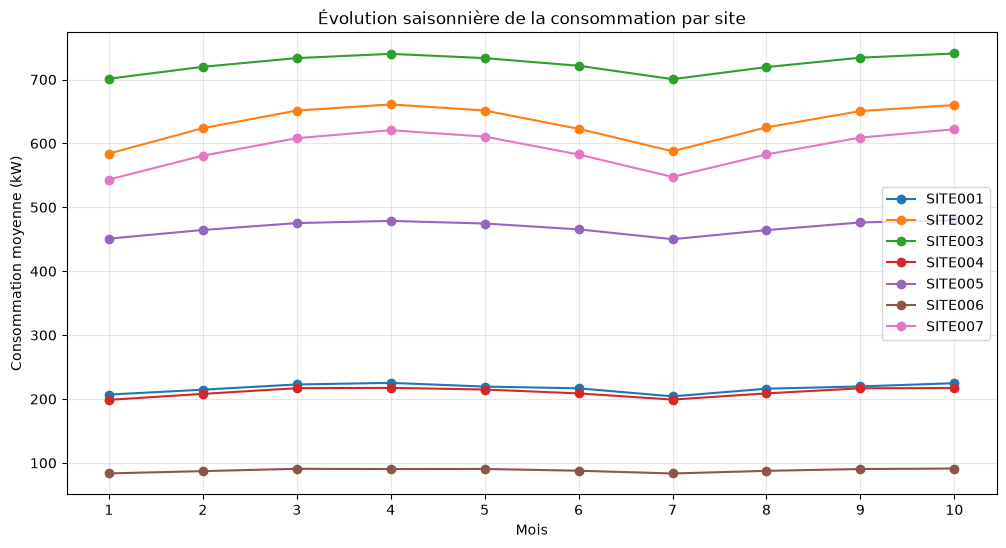

In [51]:
monthly_consumption = df.groupby(["month", "site_id"])["consumption_kw"].mean().reset_index()

plt.figure(figsize=(12, 6))

for site_id, group in monthly_consumption.groupby("site_id"):
    plt.plot(
        group["month"],
        group["consumption_kw"],
        marker="o",
        label=site_id,
    )

plt.title("Évolution saisonnière de la consommation par site")
plt.xlabel("Mois")
plt.ylabel("Consommation moyenne (kW)")
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

B - Comparaison température et consommation (sans passer par les mois)

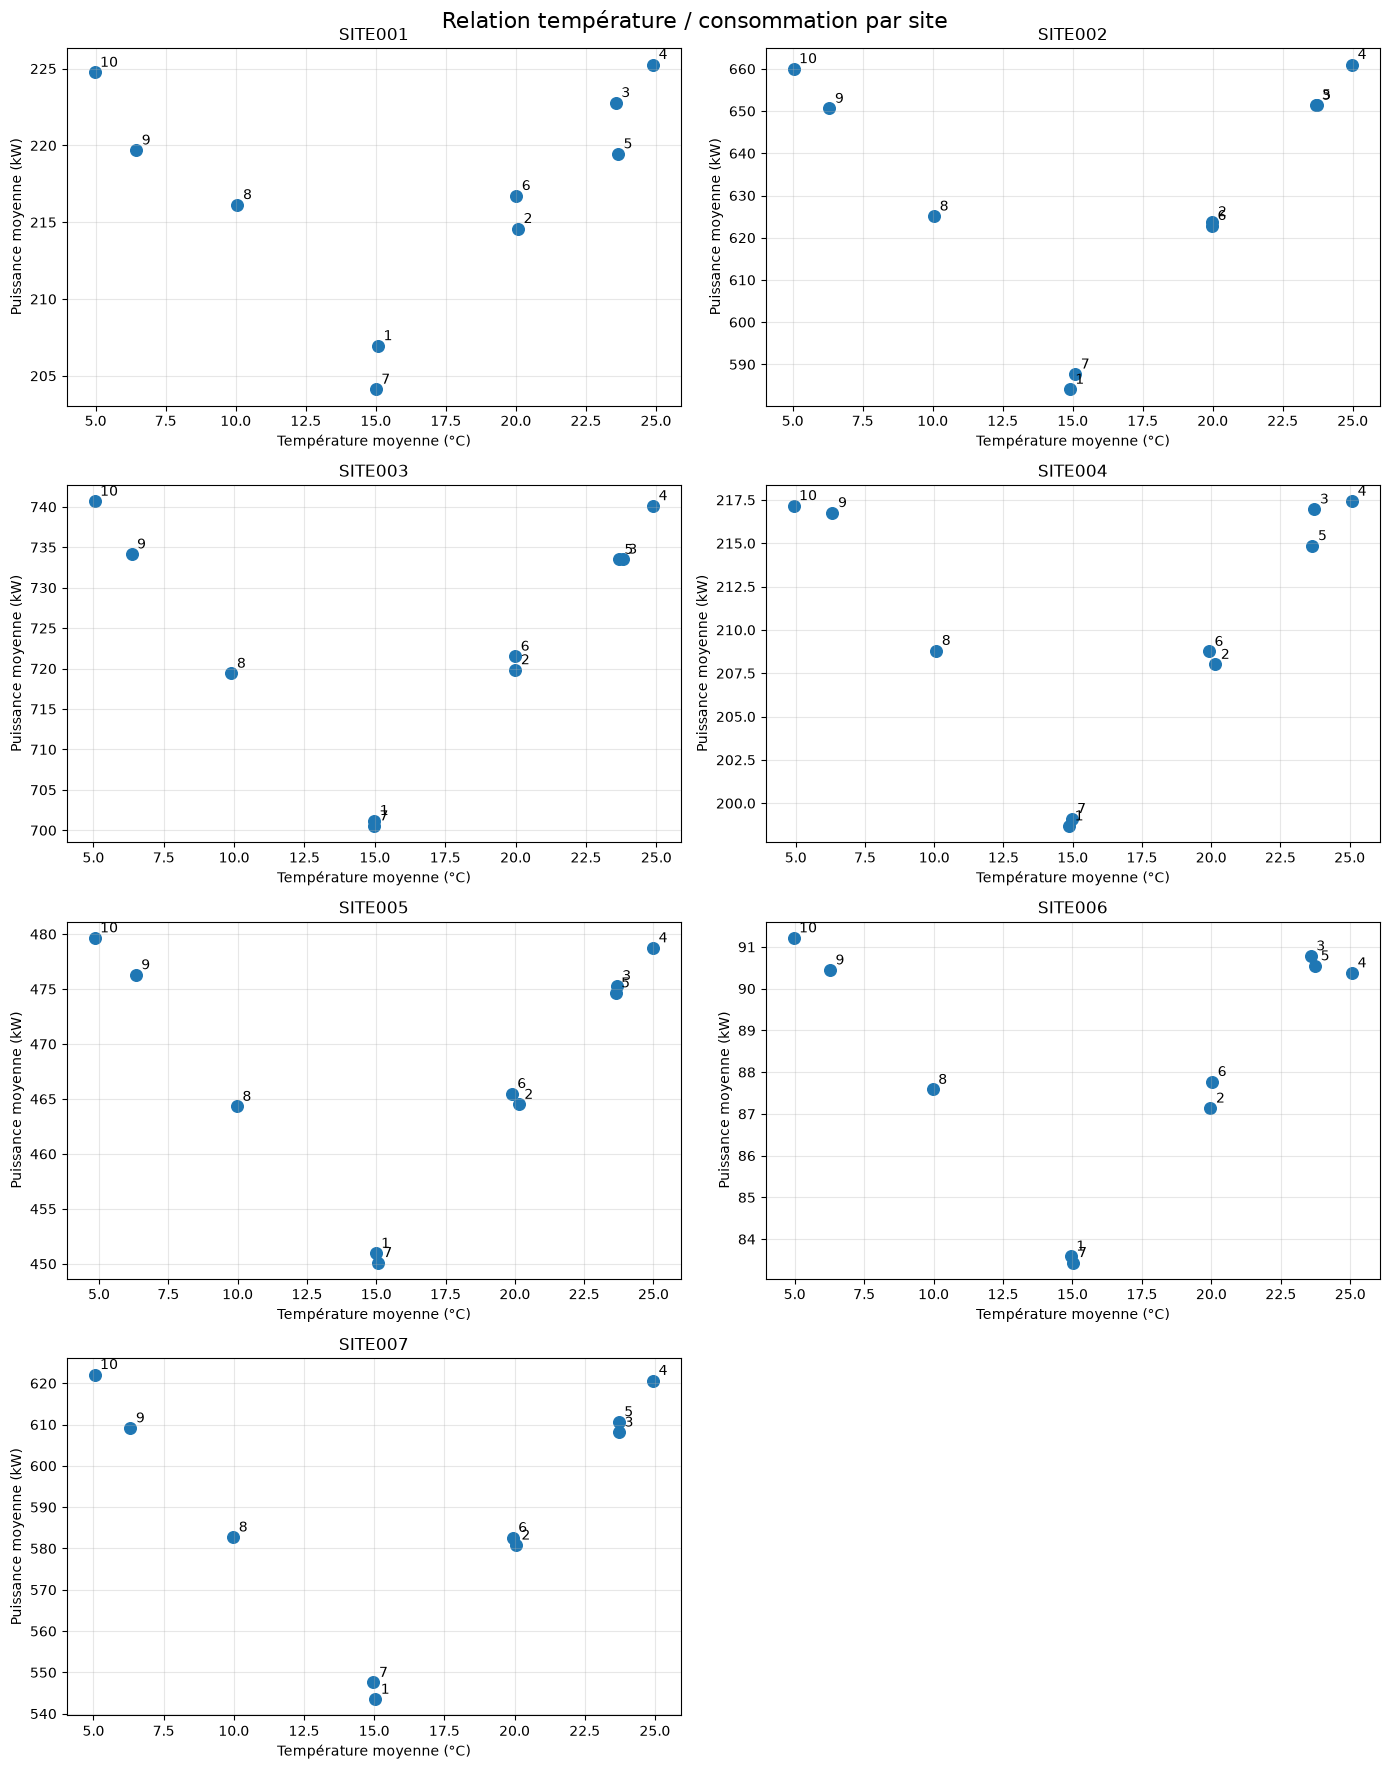

In [52]:
fig, axes = plt.subplots(4, 2, figsize=(14, 18))

axes = axes.flatten()

for i, (site_id, group) in enumerate(df.groupby("site_id")):
    monthly = (
        group.groupby("month")
        .agg(
            temperature=("temperature_celsius", "mean"),
            consumption=("consumption_kw", "mean"),
        )
        .dropna()
        .reset_index()
    )

    ax = axes[i]

    ax.scatter(
        monthly["temperature"],
        monthly["consumption"],
        s=70,
    )

    for _, row in monthly.iterrows():
        ax.annotate(
            str(int(row["month"])),
            (row["temperature"], row["consumption"]),
            xytext=(4, 4),
            textcoords="offset points",
        )

    ax.set_title(site_id)
    ax.set_xlabel("Température moyenne (°C)")
    ax.set_ylabel("Puissance moyenne (kW)")
    ax.grid(alpha=0.3)

axes[-1].axis("off")

plt.suptitle(
    "Relation température / consommation par site",
    fontsize=16,
)

plt.tight_layout()
plt.show()

### Observations et interprétation

L'analyse des sept sites EnerVision met en évidence une relation non linéaire entre la température moyenne et la puissance électrique consommée.

Pour l'ensemble des sites, la consommation présente un minimum aux alentours de 15 °C, puis augmente lorsque la température s'éloigne de cette valeur. Cette évolution prend approximativement la forme d'une courbe en U.

Les variations observées représentent des écarts relatifs estimés entre 6 % et 14 % selon les sites. Leur amplitude dépend notamment du niveau de consommation et du type d'installation.

Une hypothèse plausible serait l'influence des besoins de chauffage et de climatisation, qui augmenteraient lorsque les températures deviennent trop basses ou trop élevées. Cette explication reste néanmoins hypothétique, les données ne permettant pas d'identifier directement le fonctionnement de ces équipements.

Ces résultats suggèrent que la température constitue une variable explicative pertinente à expérimenter dans notre futur modèle prédictif, en complément des variables calendaires et des caractéristiques propres aux sites.

La relation observée étant non linéaire, nous envisagerons des transformations de variables ou des algorithmes capables de représenter ce type de comportement.

**Limites :** les observations reposent sur des données synthétiques et sur dix journées échantillonnées par site. La relation observée ne démontre pas un effet causal de la température. Son intérêt prédictif devra être confirmé par des expérimentations et une validation chronologique.

## 4 — Analyse de l'influence de l'humidité sur la consommation

### Objectif

Après avoir identifié une relation non linéaire entre la température et la consommation électrique, nous avons cherché à déterminer si l'humidité pouvait également constituer une variable explicative pertinente pour notre futur modèle prédictif.

Pour cela, nous avons comparé, pour chacun des sept sites, l'humidité moyenne et la puissance moyenne consommée sur les dix journées échantillonnées entre janvier et octobre 2026.

### Observations

Contrairement à la température, l'humidité ne présente pas de relation simple et clairement identifiable avec la consommation électrique.

Les graphiques révèlent notamment :

- Une dispersion importante des observations, sans tendance monotone évidente.
- Des niveaux de consommation parfois très différents pour des taux d'humidité relativement proches.
- Des comportements globalement similaires entre les sept sites, malgré leurs différences d'activité et de puissance.
- Une consommation particulièrement faible pour les observations de janvier et juillet, alors que leurs niveaux d'humidité sont différents.

Ces résultats suggèrent que l'humidité, considérée isolément, ne permet pas d'expliquer de manière satisfaisante les variations de consommation observées.

### Interprétation

L'humidité pourrait néanmoins intervenir indirectement dans les besoins énergétiques des bâtiments, notamment à travers les systèmes de traitement de l'air et de climatisation.

Son influence éventuelle pourrait également dépendre de la température. Il serait donc prématuré de l'écarter uniquement sur la base de ces représentations graphiques.

Par ailleurs, les deux variables météorologiques présentent des évolutions saisonnières. Les relations observées peuvent ainsi refléter des effets calendaires communs plutôt qu'une influence directe de l'humidité.

### Conclusion intermédiaire

À ce stade, la température apparaît comme une variable explicative candidate plus prometteuse que l'humidité.

Nous conserverons néanmoins cette dernière dans les variables disponibles pour nos expérimentations, afin de comparer les performances de modèles entraînés avec et sans humidité.

**Limite méthodologique :** cette analyse repose sur dix moyennes journalières par site, issues de données synthétiques. Elle ne permet ni de démontrer l'absence d'influence de l'humidité, ni de mesurer sa contribution prédictive indépendamment des autres variables.

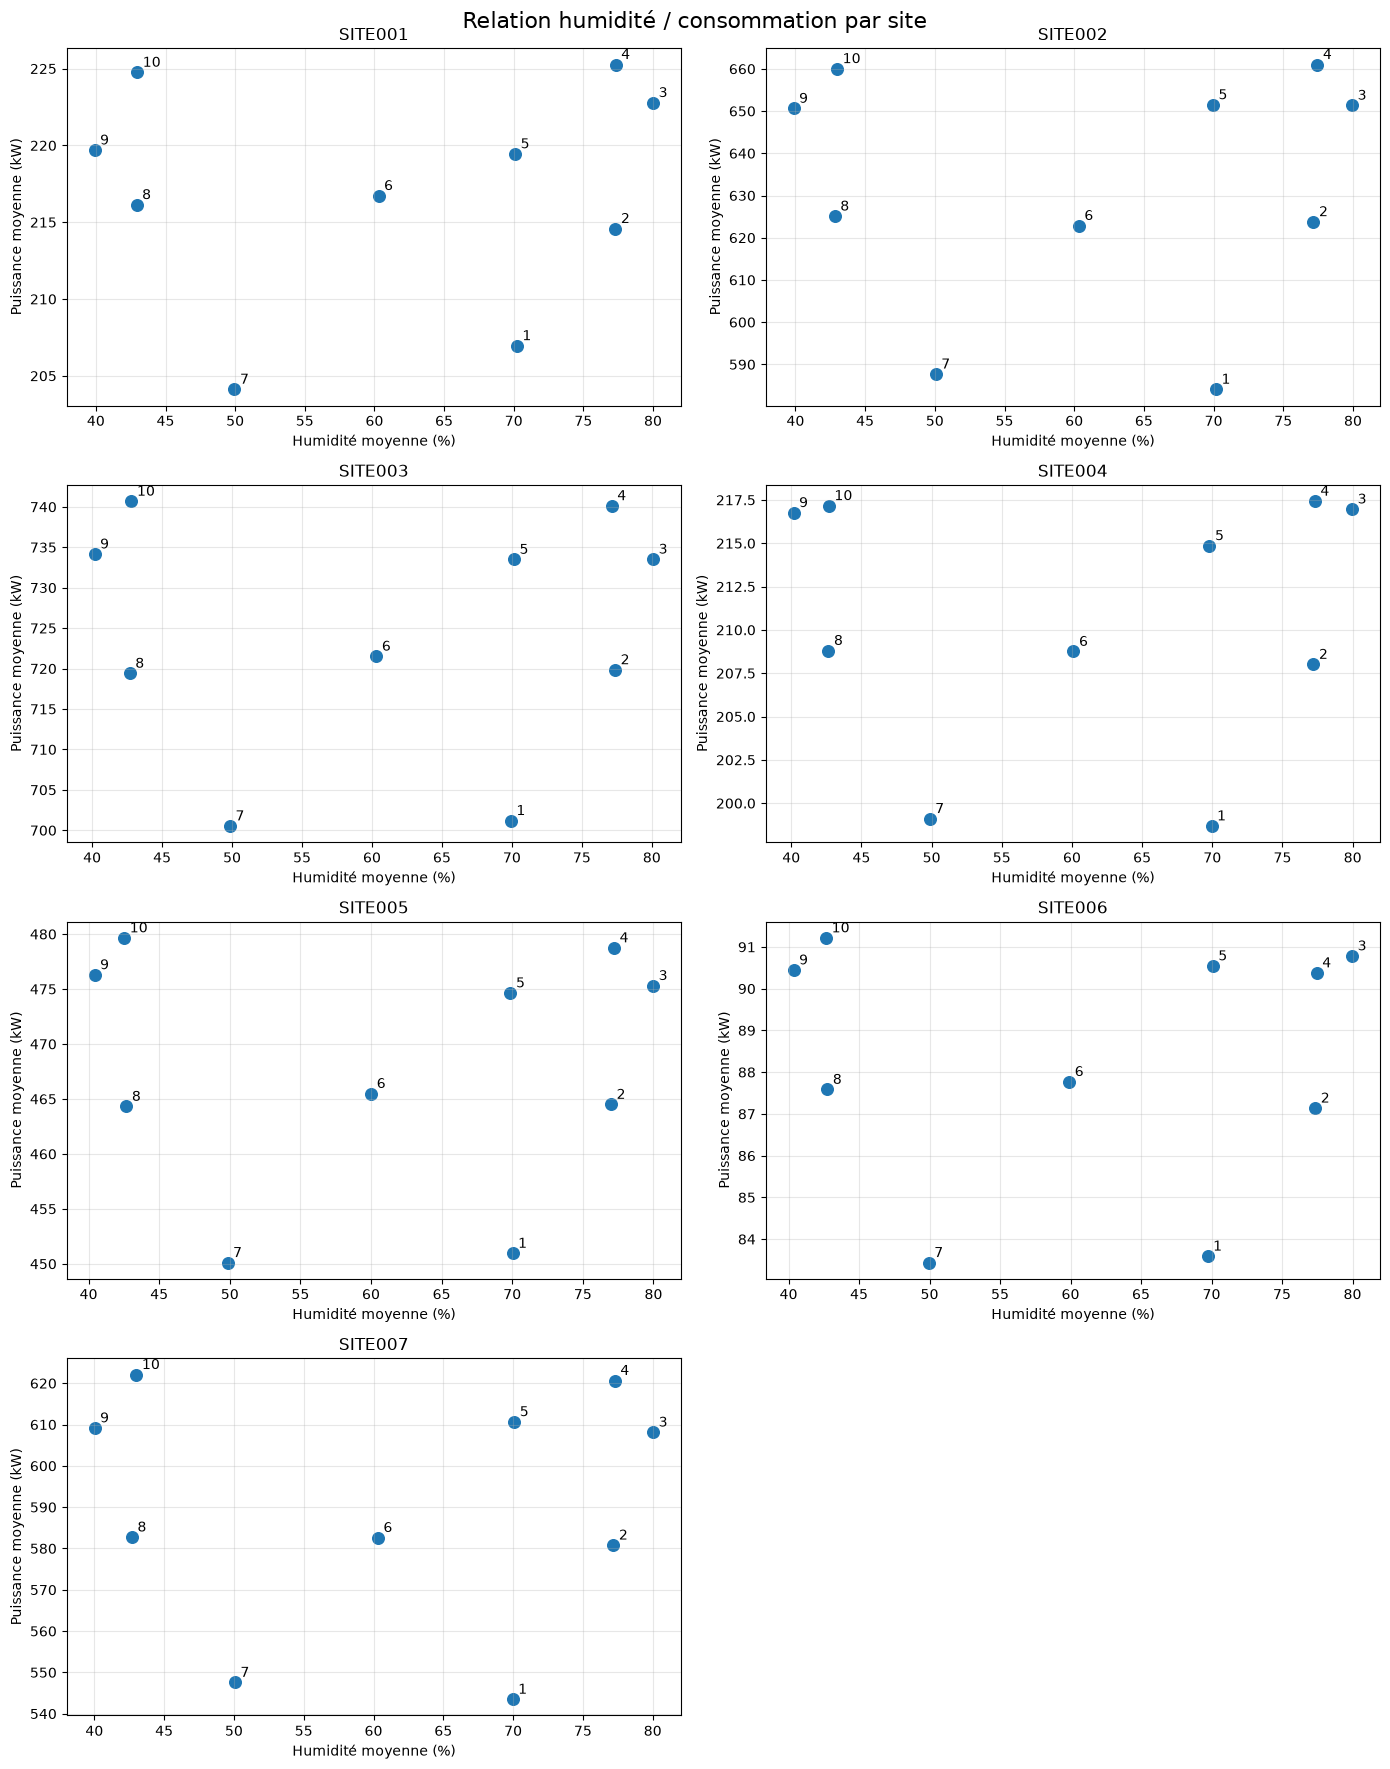

In [53]:
fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes = axes.flatten()

for i, (site_id, group) in enumerate(df.groupby("site_id")):
    monthly = (
        group.groupby("month")
        .agg(
            humidity=("humidity_percent", "mean"),
            consumption=("consumption_kw", "mean"),
        )
        .dropna()
        .reset_index()
    )

    ax = axes[i]

    ax.scatter(
        monthly["humidity"],
        monthly["consumption"],
        s=70,
    )

    for _, row in monthly.iterrows():
        ax.annotate(
            str(int(row["month"])),
            (row["humidity"], row["consumption"]),
            xytext=(4, 4),
            textcoords="offset points",
        )

    ax.set_title(site_id)
    ax.set_xlabel("Humidité moyenne (%)")
    ax.set_ylabel("Puissance moyenne (kW)")
    ax.grid(alpha=0.3)

axes[-1].axis("off")

plt.suptitle(
    "Relation humidité / consommation par site",
    fontsize=16,
)

plt.tight_layout()
plt.show()

## 5 — Conclusion de l'analyse saisonnière

### Synthèse des résultats

Cette troisième phase d'exploration avait pour objectif d'étudier les variations saisonnières de la consommation électrique et leur relation éventuelle avec les conditions environnementales.

L'étude repose sur un échantillon de **70 000 mesures théoriques**, réparties entre sept sites et dix journées d'observation, correspondant au premier mercredi de chaque mois de janvier à octobre 2026.

Plusieurs enseignements se dégagent de cette analyse.

**1. Une saisonnalité commune aux différents sites**

Les températures et les taux d'humidité suivent des évolutions saisonnières très similaires sur les sept installations.

Cette homogénéité suggère l'existence d'une composante météorologique commune dans le générateur de données synthétiques EnerVision.

Les consommations électriques présentent également des évolutions saisonnières comparables, malgré des niveaux de puissance très différents selon les installations.

**2. Une relation non linéaire entre température et consommation**

L'analyse met en évidence une relation approximativement en U entre la température moyenne et la puissance consommée.

La consommation atteint généralement son minimum aux alentours de 15 °C, puis augmente lorsque la température devient plus basse ou plus élevée.

Les écarts observés entre les températures modérées et les températures extrêmes représentent approximativement 6 à 14 % selon les sites étudiés.

Ce comportement est compatible avec une augmentation des besoins de chauffage ou de climatisation, sans que cette hypothèse puisse être confirmée à partir des seules données disponibles.

**3. Une influence de l'humidité moins évidente**

Contrairement à la température, l'humidité ne présente pas de relation directement interprétable avec la consommation.

Son éventuel intérêt prédictif reste à évaluer, notamment en combinaison avec les autres variables environnementales et temporelles.

### Conséquences pour la modélisation

En complément des analyses journalières et hebdomadaires précédentes, cette étude permet d'identifier plusieurs familles de variables candidates pour notre modèle de prévision énergétique :

| Famille | Variables candidates | Intérêt envisagé |
|---|---|---|
| Temporelle | Heure, jour de la semaine, week-end, mois | Représenter les cycles d'activité |
| Structurelle | Identifiant du site, type de site | Distinguer les profils de consommation |
| Environnementale | Température | Représenter les variations liées aux conditions thermiques |
| Environnementale | Humidité | Tester un éventuel apport complémentaire |
| Historique | Consommations passées, décalages temporels | Exploiter la continuité des séries temporelles |

La relation observée entre température et consommation justifie notamment l'expérimentation de modèles capables de représenter des comportements non linéaires, ainsi que de variables dérivées telles que l'écart à une température de référence.

Le choix définitif des variables ne sera cependant pas effectué sur la seule base de cette exploration. Il reposera sur une comparaison des performances prédictives des modèles, en utilisant une validation chronologique adaptée aux séries temporelles.

### Limites de l'étude

Plusieurs limites doivent être prises en compte :

- Les données sont synthétiques et peuvent refléter des règles propres au générateur plutôt que des comportements énergétiques réels.
- L'échantillonnage d'une seule journée par mois ne permet pas de caractériser précisément l'ensemble d'une saison.
- Les relations observées sont descriptives et ne démontrent pas de causalité.
- Les conditions météorologiques futures ne seront pas nécessairement disponibles au moment de produire les prévisions.

### Perspectives

Les trois notebooks d'exploration ont permis de caractériser les principales dimensions du jeu de données : variations horaires, rythmes hebdomadaires, différences entre sites et tendances saisonnières.

La prochaine étape consistera à préparer un jeu de données exploitable pour l'entraînement d'un modèle de **prévision de la puissance électrique moyenne à horizon de 24 heures**.

Cette préparation comprendra notamment le traitement des valeurs manquantes, la construction des variables explicatives, l'agrégation temporelle des mesures et la définition d'une stratégie de validation chronologique.

L'objectif sera de comparer plusieurs approches, depuis des modèles de référence simples jusqu'à des algorithmes de régression plus élaborés, afin d'identifier une solution adaptée aux caractéristiques et aux limites des données disponibles.